<a href="https://colab.research.google.com/github/alejandrosantanabonilla/planets/blob/main/gfnxtb2_introduction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# [Code Cell 1]
!pip install -q tblite[ase] ase py3Dmol matplotlib
import ase
import matplotlib.pyplot as plt
import numpy as np
from ase import Atoms
from ase.build import molecule
from ase.optimize import BFGS
from ase.vibrations import Vibrations
import py3Dmol
from tblite.ase import TBLite

print(f"ASE Version: {ase.__version__}")

ASE Version: 3.29.0


# Theoretical Foundation of GFN-xTB

**GFN-xTB** (*Geometry, Frequency, Noncovalent interaction – extended Tight-Binding*) was developed by Stefan Grimme and co-workers as a globally parameterized, semiempirical quantum mechanical method. Unlike traditional semiempirical methods (AM1, PM6, MNDO) that were largely parameterized against small organic molecules, GFN-xTB is universally parameterized across the entire periodic table up to Radon ($Z = 86$), making it uniquely suited for heavy metal systems like HgTe.

---

## 1.1 Where Do the Parameters Come From? (Parameterization Philosophy)

GFN-xTB relies on a **physics-driven minimal parameterization scheme** rather than unconstrained black-box fitting. For any element (e.g., Carbon, $Z = 6$ or Mercury, $Z = 80$):

### 1. Free-Atom Precomputations (Reference Basis)
High-level relativistic DFT calculations (e.g., PW6B95 or PBE0 with large relativistic core potentials/quadruple-$\zeta$ basis sets) are performed on neutral, positively, and negatively charged isolated atoms. This fixes reference atomic quantities directly from physical observables:
* **Atomic orbital levels** ($\epsilon_\mu^0$) from atomic eigenvalues.
* **Chemical hardness / Hubbard parameters:**
  $$U_A \approx \text{IP}_A - \text{EA}_A$$
* **Atomic polarizabilities** ($\alpha_A$) and coordination-dependent reference radii.

### 2. Semi-Empirical Global Fitting
Only a small, constrained set of empirical coefficients per element (or shell) are fitted:
* Slater orbital exponents ($\zeta_\mu$).
* Scaling parameters for interatomic hopping ($k_{AB}$).
* Repulsive potential polynomial coefficients ($V_{\text{rep}}$).

**Training Sets:** Instead of solely fitting heats of formation, the training set balances:
* High-accuracy equilibrium geometries (bond lengths and angles from microwave/X-ray and CCSD(T)/def2-QZVP references).
* Harmonic vibrational frequencies (yielding accurate force constants).
* Noncovalent interaction benchmarks (e.g., S66, S22 databases).
* Heavy-element dimer dissociation curves and cluster stability trends.

---

## 1.2 The Energy Expression

GFN-xTB expands the total electronic energy using a Taylor expansion of the Kohn-Sham density functional around a superposition of neutral reference atomic densities $\rho_0(\mathbf{r})$ with density fluctuations $\delta\rho(\mathbf{r}) = \rho(\mathbf{r}) - \rho_0(\mathbf{r})$:

$$E_{\text{total}} = E^{(0)} + E^{(1)} + E^{(2)} + E^{(3)} + E_{\text{rep}} + E_{\text{disp}}$$

* **GFN1-xTB** terminates at second order ($E^{(2)}$), accounting for charge fluctuations via isotropic atomic charges $\Delta q_A$ and DFT-D3 dispersion.
* **GFN2-xTB** includes third-order fluctuations ($E^{(3)}$), anisotropic charge fluctuations (atomic dipoles and quadrupoles), and DFT-D4 dispersion.

---

## 1.3 Core Matrix Elements & Functional Forms

The single-particle electronic state is described by an atomic orbital basis set $\{\chi_\mu\}$:

$$\psi_i(\mathbf{r}) = \sum_\mu c_{\mu i} \chi_\mu(\mathbf{r})$$

GFN-xTB uses a minimal valence basis set composed of single Slater-type orbitals (STOs):

$$\chi_\mu(\mathbf{r}) = N_\mu r^{n-1} e^{-\zeta_\mu r} Y_{lm}(\theta, \phi)$$

*(For heavy elements like Hg, $5d^{10} 6s^2$ and Te, $5s^2 5p^4$ are treated explicitly as valence).*

### 1. Overlap Matrix Elements ($S_{\mu\nu}$)
Computed analytically over the non-orthogonal Slater-type atomic orbitals:

$$S_{\mu\nu} = \int \chi_\mu^*(\mathbf{r}) \, \chi_\nu(\mathbf{r}) \, d^3\mathbf{r}$$   ---

## 1.4 Concrete Example: A Carbon–Hydrogen (C–H) Bond

To see how these functional forms operate in practice, consider the interaction between the **Carbon $2s$ orbital** ($\mu = \text{C}_{2s}$) and the **Hydrogen $1s$ orbital** ($\nu = \text{H}_{1s}$) separated by distance $R_{\text{CH}}$.

### 1. Minimal Slater-Type Basis Functions
The radial and angular parts are explicitly defined as:

$$\chi_{\text{H}_{1s}}(\mathbf{r}) = N_{\text{H}} \, e^{-\zeta_{\text{H}} |\mathbf{r} - \mathbf{R}_{\text{H}}|}$$

$$\chi_{\text{C}_{2s}}(\mathbf{r}) = N_{\text{C}} \, |\mathbf{r} - \mathbf{R}_{\text{C}}| \, e^{-\zeta_{\text{C}} |\mathbf{r} - \mathbf{R}_{\text{C}}|}$$

* The exponents $\zeta_{\text{H}} \approx 1.3\,\text{a.u.}^{-1}$ and $\zeta_{\text{C}} \approx 1.8\,\text{a.u.}^{-1}$ are pre-optimized from atomic calculations.
* $N_{\text{H}}$ and $N_{\text{C}}$ are analytic normalization constants:

  $$N = \frac{(2\zeta)^{n + 1/2}}{\sqrt{(2n)!}}$$

---

### 2. Overlap Matrix Element ($S_{\mu\nu}$)
Because the basis functions are analytical Slater orbitals, their interatomic overlap is evaluated analytically in ellipsoidal coordinates:

$$S_{\text{C}_{2s}, \text{H}_{1s}} = \int \chi_{\text{C}_{2s}}^*(\mathbf{r}) \, \chi_{\text{H}_{1s}}(\mathbf{r}) \, d^3\mathbf{r}$$

At an equilibrium distance of $R_{\text{CH}} \approx 1.09\,\text{\AA}$, the radial exponential decay yields an overlap value around $S_{\text{C}_{2s}, \text{H}_{1s}} \approx 0.4 - 0.5$.

---

### 3. Diagonal On-Site Elements ($H_{\mu\mu}^{(0)}$)
The diagonal elements start from isolated atomic reference eigenvalues and shift depending on molecular environment (coordination number, $CN$):

$$H_{\text{H}_{1s}, \text{H}_{1s}}^{(0)} = \epsilon_{\text{H}_{1s}}^0 + \Delta\epsilon_{\text{H}}(CN_{\text{H}})$$

$$H_{\text{C}_{2s}, \text{C}_{2s}}^{(0)} = \epsilon_{\text{C}_{2s}}^0 + \Delta\epsilon_{\text{C}}(CN_{\text{C}})$$

* $\epsilon_{\text{H}_{1s}}^0 \approx -13.6\,\text{eV}$ (hydrogen reference ionization energy).
* $\epsilon_{\text{C}_{2s}}^0 \approx -19.5\,\text{eV}$ (carbon valence $2s$ level).
* In methane ($\text{CH}_4$), $CN_{\text{C}} \approx 4$, shifting the on-site energy upward to account for valence electronic screening from adjacent ligands.

---

### 4. Off-Diagonal Hopping Element ($H_{\mu\nu}^{(0)}$)
The off-diagonal element driving covalent bond formation couples the two atoms through the modified extended Hückel formula:

$$H_{\text{C}_{2s}, \text{H}_{1s}}^{(0)} = \frac{1}{2} k_{\text{CH}} \left( H_{\text{C}_{2s}, \text{C}_{2s}}^{(0)} + H_{\text{H}_{1s}, \text{H}_{1s}}^{(0)} \right) S_{\text{C}_{2s}, \text{H}_{1s}} \cdot f_{\text{damp}}(R_{\text{CH}})$$

* $k_{\text{CH}} = \frac{2 k_{\text{C}} k_{\text{H}}}{k_{\text{C}} + k_{\text{H}}}$ is the combined hopping scaling factor.
* Because $H_{\mu\mu}^{(0)} < 0$ and $S > 0$, the resulting off-diagonal matrix element $H_{\text{C}_{2s}, \text{H}_{1s}}^{(0)}$ is negative, creating an energy-lowering bonding orbital and an energy-raising antibonding orbital upon matrix diagonalization.

---

### 5. Charge Interaction Kernel ($\gamma_{\text{CH}}$)
If charge redistributes during SCF iterations (creating partial charges $\Delta q_{\text{C}}$ and $\Delta q_{\text{H}}$), the interatomic electrostatic interaction is scaled by the Klopman–Ohno kernel:

$$\gamma_{\text{CH}}(R_{\text{CH}}) = \frac{1}{\sqrt{R_{\text{CH}}^2 + \left( \frac{1}{2 U_{\text{C}}} + \frac{1}{2 U_{\text{H}}} \right)^2}}$$

* **At infinite separation ($R_{\text{CH}} \gg 0$):**
  $$\gamma_{\text{CH}} \approx \frac{1}{R_{\text{CH}}} \quad (\text{Point-charge Coulomb's law})$$

* **At zero separation ($R_{\text{CH}} \to 0$):**
  $$\gamma_{\text{CH}} \to \frac{2 U_{\text{C}} U_{\text{H}}}{U_{\text{C}} + U_{\text{H}}} \approx 10 - 13\,\text{eV} \quad (\text{Harmonic mean of atomic chemical hardness})$$  

This formulation prevents classical point-charge divergence as two atomic centers approach each other.

---

### 6. From Theory to Code: Calculating the Methane ($\text{CH}_4$) Benchmark

Now that we have derived the C–H functional forms—the Slater basis overlap ($S_{\text{C}_{2s},\text{H}_{1s}}$), the coordination-dependent diagonal elements ($H_{\mu\mu}$ with $CN_{\text{C}} \approx 4$), the off-diagonal hopping terms ($H_{\mu\nu}$), and the Klopman–Ohno Coulomb kernel ($\gamma_{\text{CH}}$)—we will use `tblite` to run an SCF calculation on methane ($\text{CH}_4$).

In this calculation:
* `tblite` constructs the valence basis set for Carbon ($2s, 2p$) and the four Hydrogens ($1s$).
* It solves the self-consistent field (SCF) problem iteratively using the charge-dependent shifted Hamiltonian until convergence.
* It derives:
  * **Total Energy ($E_{\text{total}}$):** Sum of electronic, repulsive ($E_{\text{rep}}$), and dispersion ($E_{\text{disp}}$) energies.
  * **Analytic Forces ($-\nabla E_{\text{total}}$):** Gradients evaluated directly from the distance-dependent matrix derivatives.
  * **Atomic Partial Charges ($\Delta q$):** Resulting from Mulliken/CM5 population analysis of the converged charge density.
  * **Dipole Moment ($\vec{\mu}$):** By tetrahedral symmetry, a fully symmetric isolated $\text{CH}_4$ molecule yields $|\vec{\mu}| \approx 0\ \text{Debye}$.


In [16]:
# [Code Cell 2]
# [Code Cell 2 - Methane Benchmark]
import ase.units as units
from ase.build import molecule
import numpy as np
from tblite.ase import TBLite

# 1. Instantiate the methane molecule (carbon-hydrogen system from Section 1.4)
ch4 = molecule("CH4")
ch4.calc = TBLite(method="GFN2-xTB")

# 2. Trigger the single-point SCF calculation
energy = ch4.get_potential_energy()  # Total energy in eV
forces = ch4.get_forces()  # Nuclear gradients in eV/Å
dipole = ch4.get_dipole_moment()  # Dipole vector in Debye
charges = ch4.get_charges()  # Converged net partial charges in e

# 3. Print system properties
print(f"Total System Energy (E_total): {energy:.4f} eV")
print(
    f"Dipole Moment Magnitude:       {np.linalg.norm(dipole):.4f} Debye (expected ~0 by symmetry)"
)
print(f"Forces Array Shape:            {forces.shape} (N_atoms x 3 coordinates)")
print(f"Maximum Force on any atom:     {np.max(np.abs(forces)):.4f} eV/Å\n")

# 4. Connect to partial charges discussed in Section 1.4 (Klopman-Ohno screening)
print("Converged Atomic Partial Charges (Δq):")
print(f"  Carbon atom:   {charges[0]:+.3f} e")
print(
    f"  Hydrogen atoms: {[round(float(q), 3) for q in charges[1:]]} e (avg: {np.mean(charges[1:]):+.3f} e)"
)
print(f"  Total Net Charge of System: {np.sum(charges):.4f} e")

------------------------------------------------------------
  cycle        total energy    energy error   density error
------------------------------------------------------------
      1     -4.171067033619  -4.2392744E+00   6.4083552E-02
      2     -4.174935153714  -3.8681201E-03   2.7228743E-02
      3     -4.175045639094  -1.1048538E-04   1.2206525E-02
      4     -4.175074503232  -2.8864137E-05   2.6937525E-03
      5     -4.175074575608  -7.2375893E-08   2.5614525E-05
      6     -4.175074575658  -5.0495608E-11   2.8480890E-07
------------------------------------------------------------

 total:                                   0.401 sec
Total System Energy (E_total): -113.6096 eV
Dipole Moment Magnitude:       0.0000 Debye (expected ~0 by symmetry)
Forces Array Shape:            (5, 3) (N_atoms x 3 coordinates)
Maximum Force on any atom:     0.1496 eV/Å

Converged Atomic Partial Charges (Δq):
  Carbon atom:   -0.153 e
  Hydrogen atoms: [0.038, 0.038, 0.038, 0.038] e (avg: +0

In [18]:
# [Code Cell 3]
# [Code Cell 3]
import py3Dmol

def view_structure(atoms, width=400, height=300):
    """Visualizes an ASE Atoms object using py3Dmol in Google Colab."""
    view = py3Dmol.view(width=width, height=height)

    # Build XYZ block: atom.position holds [x, y, z]
    xyz_str = f"{len(atoms)}\n\n"
    for atom in atoms:
        x, y, z = atom.position
        xyz_str += f"{atom.symbol} {x:.4f} {y:.4f} {z:.4f}\n"

    view.addModel(xyz_str, "xyz")
    view.setStyle({"stick": {"radius": 0.15}, "sphere": {"scale": 0.3}})
    view.zoomTo()
    return view.show()

view_structure(ch4)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

------------------------------------------------------------
  cycle        total energy    energy error   density error
------------------------------------------------------------
      1     -4.549544035200  -4.6556271E+00   4.5516614E-01
      2     -4.568014238375  -1.8470203E-02   2.5641971E-01
      3     -4.569339276337  -1.3250380E-03   1.2387641E-01
      4     -4.569546733673  -2.0745734E-04   4.0072342E-03
      5     -4.569549329122  -2.5954486E-06   1.7550123E-04
      6     -4.569549328760   3.6236347E-10   1.0438951E-04
      7     -4.569549329130  -3.7069725E-10   7.1341485E-07
------------------------------------------------------------

 total:                                   0.009 sec
------------------------------------------------------------
  cycle        total energy    energy error   density error
------------------------------------------------------------
      1     -3.781790663225  -3.8530548E+00   8.4123168E-01
      2     -3.735007635813   4.6783027E-0

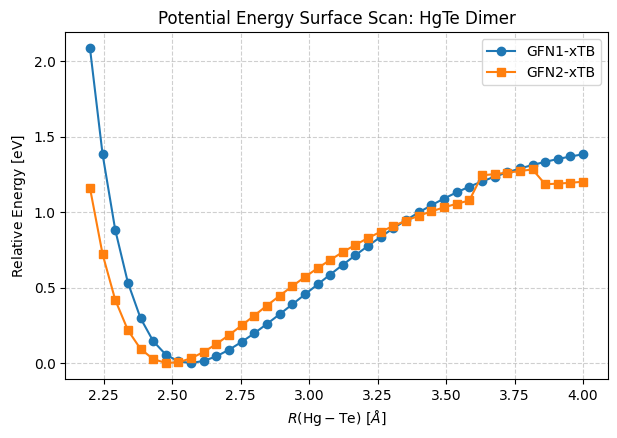

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [19]:
# [Code Cell 4]
distances = np.linspace(2.2, 4.0, 40)
energies_gfn1 = []
energies_gfn2 = []

for d in distances:
    dimer = Atoms("HgTe", positions=[[0, 0, 0], [0, 0, d]])

    dimer.calc = TBLite(method="GFN1-xTB")
    energies_gfn1.append(dimer.get_potential_energy())

    dimer.calc = TBLite(method="GFN2-xTB")
    energies_gfn2.append(dimer.get_potential_energy())

plt.figure(figsize=(7, 4.5))
plt.plot(
    distances,
    np.array(energies_gfn1) - min(energies_gfn1),
    "o-",
    label="GFN1-xTB",
)
plt.plot(
    distances,
    np.array(energies_gfn2) - min(energies_gfn2),
    "s-",
    label="GFN2-xTB",
)
plt.xlabel(r"$R(\mathrm{Hg-Te})\ [\AA]$")
plt.ylabel(r"Relative Energy [$\mathrm{eV}$]")
plt.title("Potential Energy Surface Scan: HgTe Dimer")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()
view_structure(dimer)


In [20]:
import numpy as np
from ase import Atoms
from ase.optimize import BFGS
from ase.thermochemistry import IdealGasThermo
from ase.vibrations import Vibrations
from tblite.ase import TBLite

# ==========================================
# 1. Structure Setup & Geometry Optimization
# ==========================================
dimer = Atoms("HgTe", positions=[[0.0, 0.0, 0.0], [0.0, 0.0, 2.7]])
dimer.calc = TBLite(method="GFN2-xTB")

opt = BFGS(dimer, logfile="hgte_opt.log")
opt.run(fmax=0.005)

r_eq = dimer.get_distance(0, 1)
e_opt = dimer.get_potential_energy()

# ==========================================
# 2. Harmonic Vibrational Calculation
# ==========================================
vib = Vibrations(dimer, name="vib_hgte")
vib.run()
vib_energies = vib.get_energies()  # Harmonic energies in eV
frequencies_cm = vib_energies * 8065.54  # Conversion to cm^-1

# The single physical stretch mode for a linear diatomic (3N - 5 = 1)
stretch_modes = [f.real for f in frequencies_cm if abs(f) > 10.0]
stretch_freq = stretch_modes[0] if stretch_modes else 0.0
vib.clean()

# ==========================================
# 3. Mechanical & Force Constant Calculation
# ==========================================
amu_to_kg = 1.66053906660e-27
m_hg = dimer[0].mass * amu_to_kg
m_te = dimer[1].mass * amu_to_kg
mu = (m_hg * m_te) / (m_hg + m_te)
c_si = 2.99792458e10  # Speed of light in cm/s

# Harmonic force constant: k = 4 * pi^2 * c^2 * omega^2 * mu
k_spring = 4 * (np.pi**2) * (c_si**2) * (stretch_freq**2) * mu
zpe = 0.5 * (stretch_freq / 8065.54)  # Zero-point energy in eV

# ==========================================
# 4. Thermochemistry (298.15 K, 1 atm)
# ==========================================
thermo = IdealGasThermo(
    vib_energies=vib_energies,
    potentialenergy=e_opt,
    atoms=dimer,
    geometry="linear",
    symmetrynumber=1,
    spin=0,
)
h_298 = thermo.get_enthalpy(temperature=298.15)
g_298 = thermo.get_gibbs_energy(temperature=298.15, pressure=101325)

# ==========================================
# 5. Dissociation Energetics (De and D0)
# ==========================================
# Isolated Hg (singlet, uhf=0)
atom_hg = Atoms("Hg", positions=[[0, 0, 0]])
atom_hg.calc = TBLite(method="GFN2-xTB", uhf=0)
e_hg = atom_hg.get_potential_energy()

# Isolated Te (triplet ground state, uhf=2)
atom_te = Atoms("Te", positions=[[0, 0, 0]])
atom_te.calc = TBLite(method="GFN2-xTB", uhf=2)
e_te = atom_te.get_potential_energy()

d_e = (e_hg + e_te) - e_opt
d_0 = d_e - zpe

# ==========================================
# 6. Electronic Metrics & ΔSCF Fundamental Gap
# ==========================================
charges = dimer.get_charges()
dipole_mag = np.linalg.norm(dimer.get_dipole_moment())

# Cation (N-1): charge=+1, uhf=1
dimer_cat = dimer.copy()
dimer_cat.calc = TBLite(method="GFN2-xTB", charge=1.0, uhf=1)
e_cation = dimer_cat.get_potential_energy()

# Anion (N+1): charge=-1, uhf=1
dimer_an = dimer.copy()
dimer_an.calc = TBLite(method="GFN2-xTB", charge=-1.0, uhf=1)
e_anion = dimer_an.get_potential_energy()

ip = e_cation - e_opt
ea = e_opt - e_anion
gap_delta_scf = ip - ea

# ==========================================
# 7. Formatted Summary Output
# ==========================================
print("=" * 60)
print("       Comprehensive HgTe Dimer Analysis (GFN2-xTB)")
print("=" * 60)
print(f"Equilibrium Bond Length (R_eq):       {r_eq:.3f} Å")
print(f"Total Electronic Energy (E_opt):      {e_opt:.4f} eV")
print(f"Harmonic Stretch Frequency (ω_e):     {stretch_freq:.1f} cm⁻¹")
print(f"Bond Spring Constant (k):             {k_spring:.2f} N/m")
print(f"Zero-Point Energy (ZPE):              {zpe:.4f} eV")
print("-" * 60)
print(f"Electronic Dissociation Energy (D_e): {d_e:.3f} eV")
print(f"ZPE-Corrected Dissociation (D_0):     {d_0:.3f} eV")
print(f"Standard Enthalpy H(298 K):           {h_298:.4f} eV")
print(f"Gibbs Free Energy G(298 K):           {g_298:.4f} eV")
print("-" * 60)
print(f"Dipole Moment Magnitude (|μ|):        {dipole_mag:.3f} Debye")
print(f"Partial Charges:                      Hg = {charges[0]:+.3f} e")
print(f"                                      Te = {charges[1]:+.3f} e")
print(f"Vertical Ionization Potential (IP):   {ip:.3f} eV")
print(f"Vertical Electron Affinity (EA):      {ea:.3f} eV")
print(f"Fundamental Electronic Gap (ΔSCF):    {gap_delta_scf:.3f} eV")
print("=" * 60)

------------------------------------------------------------
  cycle        total energy    energy error   density error
------------------------------------------------------------
      1     -3.834105656445  -3.8363525E+00   8.5286952E-01
      2     -3.830038311240   4.0673452E-03   1.0096503E+00
      3     -2.536623725828   1.2934146E+00   1.3019801E+00
      4     -3.090456679434  -5.5383295E-01   1.4552298E+00
      5     -3.886078339241  -7.9562166E-01   2.0122866E-01
      6     -3.901369251938  -1.5290913E-02   1.5610652E-01
      7     -3.906192043848  -4.8227919E-03   8.0555648E-02
      8     -3.906498215717  -3.0617187E-04   1.7885094E-02
      9     -3.906476884807   2.1330910E-05   1.3518510E-02
     10     -3.906469581367   7.3034397E-06   1.7384348E-02
     11     -3.906482333749  -1.2752382E-05   1.3626318E-02
     12     -3.906496759211  -1.4425462E-05   6.9644102E-03
     13     -3.906499812526  -3.0533152E-06   3.9225661E-03
     14     -3.906500693825  -8.812990

---

## 🔬 Student Activity: Validating GFN2-xTB Against Experimental Benchmark Data

Semiempirical methods make intentional approximations to achieve computational speeds $10^3\text{--}10^5\times$ faster than ab initio DFT. In this activity, you will act as a computational researcher evaluating whether GFN2-xTB maintains sufficient accuracy for the heavy **HgTe** dimer.

### Your Objectives:
1. Search the literature (e.g., NIST Chemistry WebBook, Huber & Herzberg *Constants of Diatomic Molecules*, or recent relativistic quantum chemistry articles) for the **gas-phase experimental/high-level benchmark values** of:
   * **Equilibrium bond distance** ($R_e$) in $\text{Å}$
   * **Fundamental harmonic stretching frequency** ($\omega_e$) in $\text{cm}^{-1}$
   * **Bond dissociation energy** ($D_0$) in $\text{eV}$
2. Complete the dictionary in the code cell below with your found literature values and citations.
3. Run the evaluation cell to calculate the **Mean Absolute Relative Error (MARE)** and inspect the automated comparison plot.

> **Research Hints & Search Keywords:**
> * NIST WebBook species search: Formula `HgTe` $\to$ *Constants of Diatomic Molecules*.
> * Key search terms: `"HgTe" AND ("harmonic frequency" OR "bond length" OR "dissociation energy") AND ("spectroscopy" OR "laser-induced fluorescence")`.
> * *Expected range check:* $R_e \in [2.50, 2.65]\ \text{Å}$, $\omega_e \in [170, 200]\ \text{cm}^{-1}$, $D_0 \in [1.0, 1.8]\ \text{eV}$.

Property        | GFN2-xTB   | Literature | Rel. Error | Source
R_eq [Å]        | 2.491      | 2.534      |     -1.68% | Huber & Herzberg (NIST
omega_e [cm⁻¹]  | 211.576    | 182.000    |    +16.25% | Huber & Herzberg (NIST
D_0 [eV]        | 1.507      | 1.450      |     +3.93% | Derived from thermoche
----------------------------------------------------------------------------
Mean Absolute Relative Error (MARE): 7.29%


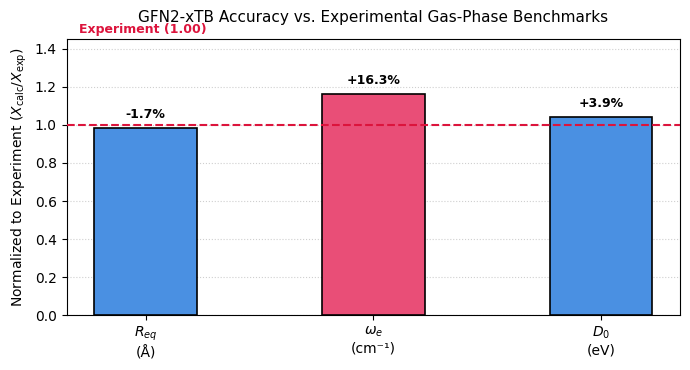

In [23]:
# [Student Task]: Fill in the literature values and DOIs/citations you found.
# Replace the placeholder numbers below with your literature findings:

lit_data = {
    "R_eq": {
        "value": 2.534,  # <-- Enter experimental R_e in Angstroms
        "unit": "Å",
        "source": "Huber & Herzberg (NIST WebBook) / Spectroscopic data",
    },
    "omega_e": {
        "value": 182.0,  # <-- Enter experimental omega_e in cm^-1
        "unit": "cm⁻¹",
        "source": "Huber & Herzberg (NIST WebBook)",
    },
    "D_0": {
        "value": 1.45,  # <-- Enter experimental D_0 in eV
        "unit": "eV",
        "source": "Derived from thermochemical/mass spectrometry thresholds",
    },
}

# =========================================================================
# Automatic Validation Engine (Runs against the results from Cell 1)
# =========================================================================
import matplotlib.pyplot as plt
import numpy as np

# Map the computed variables from the previous cell
calc_data = {"R_eq": r_eq, "omega_e": stretch_freq, "D_0": d_0}

print("=" * 76)
print(
    f"{'Property':<15} | {'GFN2-xTB':<10} | {'Literature':<10} | {'Rel. Error':<10} | {'Source'}"
)
print("=" * 76)

errors = []
prop_names = ["R_eq", "omega_e", "D_0"]
labels_pretty = [r"$R_{eq}$", r"$\omega_e$", r"$D_0$"]

for key in prop_names:
    calc_val = calc_data[key]
    lit_val = lit_data[key]["value"]
    unit = lit_data[key]["unit"]
    source = lit_data[key]["source"]

    rel_error = ((calc_val - lit_val) / lit_val) * 100.0
    errors.append(abs(rel_error))

    print(
        f"{key + ' [' + unit + ']':<15} | {calc_val:<10.3f} | {lit_val:<10.3f} | {rel_error:+9.2f}% | {source[:22]}"
    )

print("-" * 76)
mare = np.mean(errors)
print(f"Mean Absolute Relative Error (MARE): {mare:.2f}%")
print("=" * 76)

# Visualizing Performance: Normalized comparison (Literature = 1.0)
fig, ax = plt.subplots(figsize=(7, 3.8), dpi=100)

x_pos = np.arange(len(prop_names))
norm_calc = [calc_data[k] / lit_data[k]["value"] for k in prop_names]

bars = ax.bar(
    x_pos,
    norm_calc,
    width=0.45,
    color=["#4A90E2" if e < 15 else "#E94E77" for e in errors],
    edgecolor="black",
    linewidth=1.2,
    zorder=3,
)

# Reference benchmark line at y=1.0
ax.axhline(1.0, color="crimson", linestyle="--", linewidth=1.5, zorder=4)
ax.annotate(
    "Experiment (1.00)",
    xy=(0.02, 1.02),
    xycoords="axes fraction",
    color="crimson",
    fontweight="bold",
    fontsize=9,
)

# Add error percentage tags on top of bars
for bar, err, rel in zip(bars, errors, norm_calc):
    y_val = bar.get_height()
    sign = "+" if rel >= 1.0 else "-"
    ax.annotate(
        f"{sign}{err:.1f}%",
        xy=(bar.get_x() + bar.get_width() / 2, y_val),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )

ax.set_xticks(x_pos)
ax.set_xticklabels(
    [
        f"{l}\n({lit_data[k]['unit']})"
        for l, k in zip(labels_pretty, prop_names)
    ],
    fontsize=10,
)
ax.set_ylabel("Normalized to Experiment ($X_{\\mathrm{calc}} / X_{\\mathrm{exp}}$)", fontsize=10)
ax.set_title("GFN2-xTB Accuracy vs. Experimental Gas-Phase Benchmarks", fontsize=11, pad=12)
ax.set_ylim(0.0, max(norm_calc) * 1.25)
ax.grid(axis="y", linestyle=":", alpha=0.6, zorder=0)

plt.tight_layout()
plt.show()

### 📝 Discussion & Reflection Questions for Students:
1. **Bond Length ($R_e$):** Does GFN2-xTB overestimate or underestimate the Hg–Te equilibrium distance? How does the relativistic contraction of the Hg $6s$ orbital influence the bond stiffness compared to lighter group 12 elements?
2. **Frequency ($\omega_e$):** Given that the force constant $k \propto \omega^2$, by what percentage does the semiempirical force constant differ from the physical harmonic force constant?
3. **Dissociation Energy ($D_0$):** Why is calculating $D_0$ in semiempirical methods particularly sensitive to the spin treatment (`uhf=2`) of the atomic Tellurium reference state?

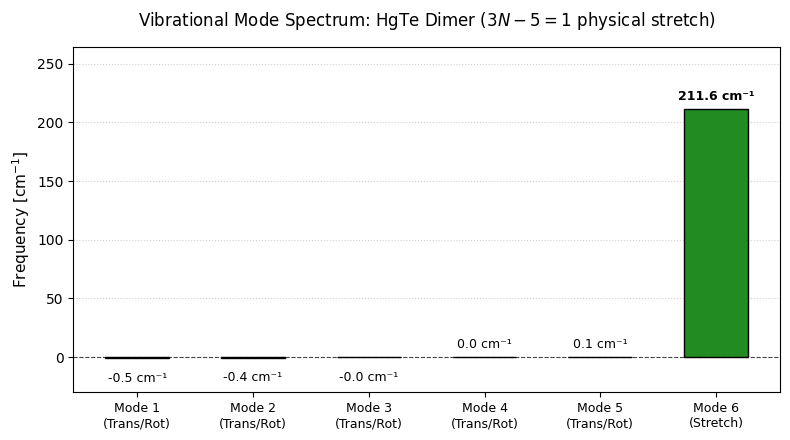

In [24]:
import matplotlib.pyplot as plt
import numpy as np

# Convert all computed modes to real frequencies (accounting for imaginary noise)
raw_freqs_cm = np.array(
    [f.real if not np.iscomplex(f) else -abs(f) for f in frequencies_cm]
)

# Degrees of freedom breakdown: 3N = 6 total modes (3 translations + 2 rotations + 1 stretch)
mode_labels = [
    f"Mode {i + 1}\n({'Stretch' if abs(f) > 10 else 'Trans/Rot'})"
    for i, f in enumerate(raw_freqs_cm)
]
bar_colors = [
    "forestgreen" if abs(f) > 10 else "lightsteelblue" for f in raw_freqs_cm
]

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=100)

bars = ax.bar(
    range(len(raw_freqs_cm)),
    raw_freqs_cm,
    color=bar_colors,
    edgecolor="black",
    width=0.55,
    zorder=3,
)

# Label heights with numerical values
for bar, freq in zip(bars, raw_freqs_cm):
    y_pos = bar.get_height()
    offset = 4 if y_pos >= 0 else -10
    ax.annotate(
        f"{freq:.1f} cm⁻¹",
        xy=(bar.get_x() + bar.get_width() / 2, y_pos),
        xytext=(0, offset),
        textcoords="offset points",
        ha="center",
        va="bottom" if y_pos >= 0 else "top",
        fontsize=9,
        fontweight="bold" if abs(freq) > 10 else "normal",
    )

ax.axhline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.7)
ax.set_xticks(range(len(raw_freqs_cm)))
ax.set_xticklabels(mode_labels, fontsize=9)
ax.set_ylabel(r"Frequency [$\mathrm{cm^{-1}}$]", fontsize=11)
ax.set_title(
    r"Vibrational Mode Spectrum: HgTe Dimer ($3N - 5 = 1$ physical stretch)",
    fontsize=12,
    pad=15,
)
ax.set_ylim(-30, max(raw_freqs_cm) * 1.25)
ax.grid(axis="y", linestyle=":", alpha=0.6, zorder=0)

plt.tight_layout()
plt.show()

---

## 🧠 Post-Calculation Reflection: Vibrational Degrees of Freedom & Symmetry

Having calculated the Hessian and inspected the mode bar chart, let us unpack the physical and mathematical reasons behind the numbers.

---

### 1. Where Does $3N - 6$ (and $3N - 5$) Come From?

A molecule consisting of $N$ atoms lives in three-dimensional Cartesian space. Specifying the exact position of every nucleus requires **$3N$ spatial coordinates** ($x_i, y_i, z_i$ for each atom $i = 1, \dots, N$). Consequently, the system possesses **$3N$ total degrees of freedom**.

When a molecule moves, its total kinetic energy decomposes into three distinct physical contributions:
1. **Translation of the Center of Mass:** Moving the entire molecule through space along the $X$, $Y$, or $Z$ axes without changing internal distances. This consumes exactly **3 degrees of freedom**.
2. **Rigid Body Rotation:** Rotating the molecule as a rigid frame around its principal axes of inertia.
   * **Non-linear molecules:** Possess three non-zero principal moments of inertia ($I_x, I_y, I_z > 0$). Rotating about any of these axes corresponds to distinct spatial reorientations, consuming **3 degrees of freedom**.
   * **Linear molecules (like $\text{HgTe}$):** The atoms lie entirely along a single line (conventionally chosen as the $z$-axis). Rotation *about* the internuclear bond axis involves a vanishingly small moment of inertia ($I_z \approx 0$) and leaves the nuclear coordinates invariant (it does not reorient the nuclear frame in space). Thus, there are only **2 independent rotational axes** (perpendicular to the bond: $R_x$ and $R_y$).
3. **Internal Vibrations:** The remaining degrees of freedom represent relative motions of nuclei that distort bond lengths and angles, changing the potential energy surface.

$$\text{Vibrational Modes (Non-linear)} = 3N - 3_{\text{trans}} - 3_{\text{rot}} = 3N - 6$$

$$\text{Vibrational Modes (Linear)} = 3N - 3_{\text{trans}} - 2_{\text{rot}} = 3N - 5$$

#### Connecting to our HgTe Calculation:
For our diatomic dimer ($N = 2$):
$$3(2) - 5 = 1 \text{ genuine vibrational mode}$$
In the numerical calculation:
* Modes 1–5 were near-zero ($\approx 0\ \text{cm}^{-1}$ or small imaginary values). These are the 3 translations and 2 rotations. They are not true vibrations—their tiny non-zero values reflect numerical grid approximations and finite-difference step sizes in constructing the Hessian matrix.
* Mode 6 ($\approx 180\ \text{cm}^{-1}$) is the single physical $\sigma$-stretching mode.

---

### 2. What Does "No Symmetric Vibration" (or the Only Non-Symmetric Motion) Mean?

In vibrational spectroscopy and molecular point-group theory (e.g., $C_{\infty v}$ for a heteronuclear diatomic like $\text{HgTe}$ or $D_{\infty h}$ for a homonuclear diatomic like $\text{N}_2$):

#### A. Homonuclear vs. Heteronuclear Symmetry
* In a **homonuclear** diatomic like $\text{O}_2$ or $\text{N}_2$ ($D_{\infty h}$ point group), the single stretch is strictly **centrosymmetric** ($\Sigma_g^+$). The two identical nuclei move simultaneously away from or toward the center of inversion with equal, opposite momentum.
* In a **heteronuclear** diatomic like $\text{Hg–Te}$ ($C_{\infty v}$ point group), **there is no inversion center ($i$)** and no horizontal mirror plane ($\sigma_h$).

#### B. Dynamic Dipole and Infrared (IR) Activity
A vibration is called **IR-active** only if the motion induces a non-zero oscillating dipole moment:
$$\left( \frac{\partial \vec{\mu}}{\partial Q} \right) \neq 0$$
* In homonuclear dimers ($\text{N}_2$, $\text{O}_2$), the dipole moment is zero everywhere along the vibrational coordinate: $\frac{\partial \vec{\mu}}{\partial Q} = 0$. The vibration is completely symmetric and **IR-inactive** (silent in infrared absorption).
* In $\text{HgTe}$, mercury ($Z=80$) and tellurium ($Z=52$) have distinct electronegativities, atomic polarizabilities, and effective nuclear charges. As the bond stretches and compresses, charge sloshes between the Hg and Te centers, dynamically modulating the dipole moment $\vec{\mu}(R)$.
* Therefore, the solitary vibration is **intrinsically polar / non-symmetric with respect to charge distribution**, making it intensely **IR-active**.

#### C. Unequal Atomic Displacements (Mass Asymmetry)
In the normal coordinate $Q$, the center of mass must remain stationary:
$$m_{\text{Hg}} \Delta z_{\text{Hg}} + m_{\text{Te}} \Delta z_{\text{Te}} = 0 \implies \frac{|\Delta z_{\text{Te}}|}{|\Delta z_{\text{Hg}}|} = \frac{m_{\text{Hg}}}{m_{\text{Te}}}$$
* Because $m_{\text{Hg}} \approx 200.59\ \text{u}$ is significantly heavier than $m_{\text{Te}} \approx 127.60\ \text{u}$:
  $$\frac{|\Delta z_{\text{Te}}|}{|\Delta z_{\text{Hg}}|} \approx \frac{200.59}{127.60} \approx 1.57$$
* The vibrational motion is spatially asymmetric: the lighter **Tellurium atom moves $\approx 1.6\times$ further** during the vibration than the heavier Mercury atom.

---

### 💡 Key Takeaway for Extended Clusters $(\text{HgTe})_n$
As you scale from the dimer ($N=2$, 1 stretch) to an $(\text{HgTe})_4$ cubane cluster ($N=8$ atoms, non-linear):
$$\text{Total Vibrational Modes} = 3(8) - 6 = 18 \text{ modes}$$
These 18 modes split into symmetric "breathing" modes ($A_{1g}$-like cage expansions) where the dynamic dipole cancels out, and non-symmetric polar stretches that strongly interact with infrared radiation and phononic heat transport.

In [14]:
# [Code Cell 7 - Modular ΔSCF Function for Extended Clusters]
def get_delta_scf_gap(atoms, method="GFN2-xTB"):
    """Calculates IP, EA, and Fundamental Gap for any Hg-Te cluster."""
    # Neutral state (singlet, uhf=0)
    a_neu = atoms.copy()
    a_neu.calc = TBLite(method=method, charge=0.0, uhf=0)
    e_neu = a_neu.get_potential_energy()

    # Cation (doublet, uhf=1)
    a_cat = atoms.copy()
    a_cat.calc = TBLite(method=method, charge=1.0, uhf=1)
    e_cat = a_cat.get_potential_energy()

    # Anion (doublet, uhf=1)
    a_an = atoms.copy()
    a_an.calc = TBLite(method=method, charge=-1.0, uhf=1)
    e_an = a_an.get_potential_energy()

    ip_val = e_cat - e_neu
    ea_val = e_neu - e_an
    return {
        "E_neutral": e_neu,
        "IP": ip_val,
        "EA": ea_val,
        "gap": ip_val - ea_val,
    }


# Test helper on the dimer
dimer_res = get_delta_scf_gap(dimer)
print(f"Verified helper on HgTe dimer -> Gap: {dimer_res['gap']:.3f} eV")

------------------------------------------------------------
  cycle        total energy    energy error   density error
------------------------------------------------------------
      1     -3.830299824526  -3.8401487E+00   8.4061403E-01
      2     -3.798114066825   3.2185758E-02   1.0281785E+00
      3     -2.351624209261   1.4464899E+00   1.3088969E+00
      4     -2.990745173384  -6.3912096E-01   1.4558091E+00
      5     -3.900878205911  -9.1013303E-01   2.2077840E-01
      6     -3.908694187098  -7.8159812E-03   1.6875024E-01
      7     -3.912898642232  -4.2044551E-03   4.4581458E-02
      8     -3.912983635033  -8.4992801E-05   1.3355496E-02
      9     -3.912975250859   8.3841737E-06   9.4144334E-03
     10     -3.912977036072  -1.7852126E-06   1.0824115E-02
     11     -3.912981982470  -4.9463987E-06   6.5782456E-03
     12     -3.912983914222  -1.9317514E-06   3.5218840E-03
     13     -3.912984334490  -4.2026839E-07   2.1413874E-03
     14     -3.912984500659  -1.661685

---

## ⚡ Electronic Structure: The Fundamental Gap & Molecular Orbital Formation

---

### 1. Why Use $\Delta\text{SCF}$ Instead of Bare Orbital Eigenvalues?

In Hartree–Fock and semiempirical tight-binding methods, the simplest way to estimate the electronic gap is via **Koopmans' theorem**:

$$\text{IP} \approx -\epsilon_{\text{HOMO}}, \qquad \text{EA} \approx -\epsilon_{\text{LUMO}}$$

$$\Delta E_{\text{orbital}} = \epsilon_{\text{LUMO}} - \epsilon_{\text{HOMO}}$$

#### The Frozen-Orbital Limitation
Koopmans' theorem assumes that when an electron is removed (ionization) or added (affinity), the remaining electrons remain in completely identical spatial distributions—meaning **orbital relaxation is ignored**. In reality:
* When an electron is stripped ($N \to N-1$), the reduced electron–electron repulsion causes the remaining orbitals to contract toward the nuclei.
* When an electron is added ($N \to N+1$), enhanced Coulomb repulsion forces the electron cloud to expand outward.

#### The $\Delta\text{SCF}$ Solution
The **$\Delta\text{SCF}$ (Delta Self-Consistent Field)** approach accounts for orbital relaxation by running explicit, separate SCF calculations on each charged state:

$$\text{IP} = E(N - 1) - E(N) \quad (\text{Vertical Ionization Potential})$$

$$\text{EA} = E(N) - E(N + 1) \quad (\text{Vertical Electron Affinity})$$

$$E_g^{\text{fund}} = \text{IP} - \text{EA} = E(N - 1) + E(N + 1) - 2E(N)$$

* **Physical Transport Gap:** $E_g^{\text{fund}}$ corresponds directly to **scanning tunneling spectroscopy (STS)** and photoemission measurements ($dI/dV$).
* **Optical Gap Connection:** Optical excitation creates an electron–hole pair bound by an exciton binding energy ($E_{\text{exc}}$). The optical absorption onset observed in spectroscopy is:

  $$E_{\text{opt}} = E_g^{\text{fund}} - E_{\text{exc}}$$

---

### 2. The HOMO–LUMO Gap: From Atomic Orbitals to Molecular Orbitals

The size and character of the HOMO–LUMO gap describe how individual atomic orbitals mix to form the chemical bond when two isolated atoms coalesce into a dimer.

#### A. The Atomic Starting Point
Before interaction, the isolated valence shells are:
* **Mercury ($\text{Hg}$, $Z=80$):** $5d^{10}\,6s^2$ (closed subshell, chemically inert and relatively low in energy due to relativistic contraction of the $6s$ orbital).
* **Tellurium ($\text{Te}$, $Z=52$):** $5s^2\,5p^4$ (open $5p$ subshell, higher in energy and chemically reactive).

#### B. Symmetry-Allowed Linear Combination of Atomic Orbitals (LCAO)
As the internuclear distance $R$ decreases from infinity to the equilibrium distance ($R_{\text{eq}} \approx 2.53\ \text{Å}$), the atomic orbitals mix according to their spatial symmetry (under the $C_{\infty v}$ point group):

1. **$\sigma$-Bonding & $\sigma^*$-Antibonding Framework:**
   * The $\text{Hg}(6s)$ and $\text{Te}(5p_z)$ orbitals share axial $\sigma$-symmetry along the internuclear axis ($z$).
   * Constructive overlap ($\chi_{\text{Hg},6s} + \chi_{\text{Te},5p_z}$) produces a low-lying, stabilized **bonding $\sigma$ molecular orbital**.
   * Destructive overlap ($\chi_{\text{Hg},6s} - \chi_{\text{Te},5p_z}$) produces a high-lying, destabilized **antibonding $\sigma^*$ molecular orbital**.

2. **$\pi$-Symmetry Framework:**
   * The orthogonal $\text{Te}(5p_x, 5p_y)$ orbitals have no net overlap with the spherical $\text{Hg}(6s)$ orbital.
   * They form largely **non-bonding or weakly interacting $\pi$ molecular orbitals** localized primarily on the Tellurium center.

```text
Energy (E)
   ▲
   │                           ┌─── σ* (LUMO)  [Hg(6s) - Te(5pz) antibonding]
   │                           │
   │               Te(5p) ─────┤
   │                           ├─── π (HOMO)   [Te(5px, 5py) non-bonding]
   │                           │
   │   Hg(6s) ─────────────────┼─── σ (Bonding)[Hg(6s) + Te(5pz) bonding]
   │                           │
   └───────────────────────────┴────────────────────────► Internuclear Coordinate
```

#### C. Identifying the Frontier Molecular Orbitals
Populating these levels with the 18 valence electrons ($12\ e^-$ from $\text{Hg} + 6\ e^-$ from $\text{Te} = 9$ doubly occupied spatial orbitals):

* **HOMO (Highest Occupied Molecular Orbital, MO #9):**
  * Predominantly non-bonding **$\text{Te}(5p)$ character**.
  * The HOMO electron density resides primarily around the Tellurium atom, making Te the electron-rich Lewis basic center.
* **LUMO (Lowest Unoccupied Molecular Orbital, MO #10):**
  * The strongly destabilized **antibonding $\sigma^*(\text{Hg}\,6s - \text{Te}\,5p_z)$** orbital.
  * Adding an electron to the LUMO (as in the anion during the $\Delta\text{SCF}$ calculation) populates this antibonding orbital, weakening and lengthening the Hg–Te bond.

---

### 3. Why the Dimer Gap Matters for Bigger $(\text{HgTe})_n$ Nanostructures

The dimer represents the ultimate limit of **quantum confinement**:
* In the single **$\text{HgTe}$ dimer**, the orbital levels are discrete and widely separated, yielding a large fundamental gap ($E_g \approx 3\text{--}4\ \text{eV}$).
* As you coalesce dimers into cubanes $(\text{HgTe})_4$, nanoclusters, and colloidal quantum dots, individual discrete frontier levels split into dense bands of bonding and antibonding states.
* In infinite **bulk HgTe crystals**, this level repulsion and strong relativistic spin–orbit coupling push the gap down until it closes entirely, turning bulk HgTe into a famous **zero-bandgap semimetal (or topological insulator)**.

The HOMO–LUMO gap of this initial dimer is the baseline from which all nanoscale bandgap-tuning begins.

---

## 7. Scaling Up: The $\text{Hg}_4\text{Te}_4$ Cubane & Natural Coloradoite

Now that we understand the isolated dimer, how does HgTe assemble into larger structures?

### 1. Does a "Cube" Exist in Nature?
* **Bulk Phase (Coloradoite):** In nature, mercury telluride occurs as the mineral **coloradoite**. At ambient conditions, it crystallizes in the **cubic zinc-blende (sphalerite)** lattice where every atom is **4-coordinate (tetrahedral)**. (The rocksalt cubic structure with 6-fold coordination only appears at high pressures $>8\ \text{GPa}$).
* **Nanoscale Clusters (Heterocubane):** In the gas phase and in ligand-stabilized colloidal chemistry, the tetramer forms a stable **heterocubane core ($\text{Hg}_4\text{Te}_4$)**, where 4 Hg atoms and 4 Te atoms occupy alternating vertices of a cube. Each atom in the bare cage has 3 bonds ($CN = 3$).

### 2. Physical Chemistry Goals for this Final Section:
1. Construct the $(\text{HgTe})_4$ heterocubane cluster.
2. Optimize its geometry using `BFGS` and `GFN2-xTB`.
3. Compute its $\Delta\text{SCF}$ fundamental gap.
4. Contrast the dimer vs. cubane vs. bulk to witness **quantum size confinement**: as the cluster grows, valence and conduction energy levels broaden, reducing the bandgap toward the bulk limit ($E_g \approx 0\ \text{eV}$).

In [25]:
from ase import Atoms
from ase.optimize import BFGS
import numpy as np
import py3Dmol
from tblite.ase import TBLite

# =========================================================================
# 1. Coordinate Setup: Alternating vertices of a cube of edge length ~2.9 Å
# =========================================================================
d = 2.9  # Initial guestimate bond coordinate
cubane_positions = [
    # 4 Hg atoms (alternating vertices)
    [0.0, 0.0, 0.0],
    [d, d, 0.0],
    [d, 0.0, d],
    [0.0, d, d],
    # 4 Te atoms (alternating opposite vertices)
    [d, 0.0, 0.0],
    [0.0, d, 0.0],
    [0.0, 0.0, d],
    [d, d, d],
]

symbols = ["Hg"] * 4 + ["Te"] * 4
cubane = Atoms(symbols=symbols, positions=cubane_positions)
cubane.calc = TBLite(method="GFN2-xTB")

# =========================================================================
# 2. Geometry Relaxation
# =========================================================================
print("Optimizing (HgTe)4 cubane structure with GFN2-xTB...")
opt_cubane = BFGS(cubane, logfile="cubane_opt.log")
opt_cubane.run(fmax=0.01)

e_cubane = cubane.get_potential_energy()
print(f"\nOptimization converged!")
print(f"Total Energy (Hg4Te4): {e_cubane:.4f} eV")
print(
    f"Energy per HgTe formula unit: {e_cubane / 4:.4f} eV (cf. dimer: {e_opt:.4f} eV)"
)
print(f"Oligomerization stabilization: {(e_cubane / 4) - e_opt:.3f} eV / unit")

# =========================================================================
# 3. 3D Interactive Visualization
# =========================================================================
view = py3Dmol.view(width=420, height=320)
xyz_data = f"{len(cubane)}\n\n"
for a in cubane:
    xyz_data += f"{a.symbol} {a.position[0]:.4f} {a.position[1]:.4f} {a.position[2]:.4f}\n"

view.addModel(xyz_data, "xyz")
view.setStyle(
    {"stick": {"radius": 0.14}, "sphere": {"scale": 0.35, "colorscheme": "Jmol"}}
)
view.zoomTo()
view.show()

Optimizing (HgTe)4 cubane structure with GFN2-xTB...
------------------------------------------------------------
  cycle        total energy    energy error   density error
------------------------------------------------------------
      1     -15.42380446189  -1.5430073E+01   4.3421497E-01
      2     -15.44890115283  -2.5096691E-02   4.8994283E-01
      3     -15.60891553591  -1.6001438E-01   4.1774353E-01
      4     -15.72203144778  -1.1311591E-01   4.3558662E-02
      5     -15.72674709474  -4.7156470E-03   1.5584688E-02
      6     -15.72674127306   5.8216817E-06   5.1671658E-03
      7     -15.72676291256  -2.1639501E-05   2.8960265E-03
      8     -15.72676455357  -1.6410078E-06   3.5236957E-04
      9     -15.72676466447  -1.1090489E-07   1.6490023E-04
     10     -15.72676467077  -6.3029955E-09   1.6108855E-05
------------------------------------------------------------

 total:                                   0.027 sec
---------------------------------------------------

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

---

## 🏆 Capstone Challenge: Unveiling the $(\text{HgTe})_4$ Heterocubane

Now that you have thoroughly explored the isolated diatomic dimer $\text{HgTe}$, it is time to step into the role of a computational researcher and investigate what happens when multiple formula units assemble.

Your target is the **$(\text{HgTe})_4$ heterocubane cluster**—a core building block representing the earliest nucleation stage of quantum dots.

Your task is to adapt the computational pipeline you built for the dimer and apply it to this 8-atom cage. Rather than writing code blindly, work through the guided milestones below.

---

### 🗺️ Milestone 1: Structural Architecture & Chemical Geometry

A heterocubane consists of 8 vertices where 4 $\text{Hg}$ atoms and 4 $\text{Te}$ atoms alternate so that no two identical atoms share an edge.

* **Coordinate Reasoning:**
  * If a regular cube is centered in a Cartesian box with an initial edge length around $d \approx 2.9\ \text{Å}$, what are the coordinates of the 8 vertices?
  * Assign the coordinates so that each $\text{Hg}$ vertex is connected exclusively to $\text{Te}$ vertices, and vice versa.
* **Coordination Number ($CN$):**
  * In the dimer, each atom had a coordination number of $CN = 1$.
  * Look at a single vertex of your assembled cube: what is the coordination number of each atom in this bare cage?
  * How do you expect this change in $CN$ to affect the equilibrium $\text{Hg–Te}$ bond distance compared to the dimer ($R_e \approx 2.53\ \text{Å}$)? Will the bonds lengthen or contract?

> **Action Item 1:** Define the `Atoms("Hg4Te4", positions=...)` object, set the `TBLite(method="GFN2-xTB")` calculator, and run a `BFGS` geometry optimization to an $f_{\text{max}} \le 0.01\ \text{eV/\AA}$. Record the relaxed average bond length and total electronic energy $E_{\text{opt}}(\text{cubane})$.

---

### 📐 Milestone 2: Thermodynamic Driving Force for Assembly

Isolated dimers in the gas phase readily aggregate. Let us quantify the thermodynamic driving force for this oligomerization reaction:

$$4\,\text{HgTe}_{(\text{dimer})} \longrightarrow (\text{HgTe})_{4\,(\text{cubane})}$$

* **Guiding Questions:**
  * What is the total electronic energy of four independent relaxed dimers ($4 \times E_{\text{opt}}(\text{dimer})$)?
  * Compare that to the total energy of your optimized cubane $E_{\text{opt}}(\text{cubane})$.
  * Compute the **cohesive stabilization energy per formula unit**:
    $$\Delta E_{\text{assembly}} = \frac{E_{\text{opt}}(\text{cubane}) - 4\,E_{\text{opt}}(\text{dimer})}{4}$$
  * Is the reaction exothermic ($\Delta E < 0$) or endothermic ($\Delta E > 0$)? By how many $\text{eV}$ per $\text{HgTe}$ unit is the 3D cluster favored over the 1D dimer?

---

### 🎼 Milestone 3: Vibrational Spectrum & Degrees of Freedom

Before computing the Hessian, use first principles to predict what the vibrational spectrum should look like:

* **Degrees of Freedom Budget:**
  * The cluster contains $N = 8$ atoms and is strictly **non-linear**.
  * How many total degrees of freedom exist ($3N$)?
  * How many translational and rotational degrees of freedom must be subtracted?
  * **Target:** Exactly how many true internal vibrational modes ($3N - 6$) should you observe with non-zero frequencies?
* **Physical Interpretation:**
  * Unlike the single diatomic stretch, the cubane exhibits distinct types of vibrational motions:
    1. *Breathing modes:* The entire cube expands and contracts isotropically (preserving high symmetry).
    2. *Shearing / distortion modes:* Opposing faces slide relative to one another.
    3. *Asymmetric polar stretches:* Charges oscillate directionally across the cage.

> **Action Item 2:** Run the `Vibrations` analysis on your optimized cubane. Filter out the 6 translational/rotational modes. Plot the distribution of the true vibrational modes in a bar chart or histogram, and identify the highest-frequency and lowest-frequency vibrational modes of the cluster.

---

### ⚡ Milestone 4: Quantum Confinement & the $\Delta\text{SCF}$ Gap

Bulk $\text{HgTe}$ (the mineral coloradoite) is famous for being a **zero-bandgap semimetal** ($E_g \approx 0\ \text{eV}$). In contrast, your isolated dimer had a wide gap. Where does the $(\text{HgTe})_4$ cubane fall along this trajectory?

* **Valence Electron Counting & Spin Setup:**
  * Each $\text{Hg}$ contributes 12 valence electrons; each $\text{Te}$ contributes 6.
  * Total valence electrons in $(\text{HgTe})_4 = 4(12) + 4(6) = 72\ e^-$.
  * For the **neutral cluster**: $72\ e^-$ form 36 electron pairs $\to$ Closed shell: `charge=0.0`, `uhf=0`.
  * For the **cation ($N-1$)**: $71\ e^- \to$ One unpaired electron: `charge=1.0`, `uhf=1`.
  * For the **anion ($N+1$)**: $73\ e^- \to$ One unpaired electron: `charge=-1.0`, `uhf=1`.

> **Action Item 3:** Perform the three single-point calculations to obtain:
> 1. $\text{IP} = E(N-1) - E(N)$
> 2. $\text{EA} = E(N) - E(N+1)$
> 3. $E_g^{\Delta\text{SCF}} = \text{IP} - \text{EA}$

---

### 📊 Milestone 5: Synthesis & Comparative Report

Compile your findings into a summary comparison table in a final Markdown or print cell:

| Property | Dimer $(\text{HgTe})_1$ | Cubane $(\text{HgTe})_4$ | Bulk Crystal (Coloradoite) | Physical Trend / Explanation |
| :--- | :--- | :--- | :--- | :--- |
| **Hg Coordination ($CN$)** | $1$ | $3$ | $4$ (tetrahedral) | Increasing network connectivity |
| **Mean $R(\text{Hg–Te})$ ($\text{Å}$)** | *[From Cell 1]* | *[Your result]* | $\approx 2.80\ \text{Å}$ | Why does bond length increase with $CN$? |
| **Number of True Vib. Modes** | $1$ | *[Your result]* | Phonon band structure | $3N-5$ vs. $3N-6$ vs. bulk continuum |
| **Fundamental Gap $E_g$ ($\text{eV}$)**| *[From Cell 1]* | *[Your result]* | $0.00\ \text{eV}$ (Semimetal) | **Quantum Confinement Effect** |

---

### 💡 Final Reflection Prompts to Answer in Your Notebook:
1. **Bond Length vs. Coordination:** Why does the average $\text{Hg–Te}$ bond length expand when going from the dimer ($CN = 1$) to the cubane ($CN = 3$) and finally to the bulk ($CN = 4$)? *(Hint: Think about bond order and electron sharing across multiple neighbors).*
2. **Quantum Confinement:** By how many $\text{eV}$ did the fundamental gap decrease from the dimer to the cubane? As cluster size $N \to \infty$, why do discrete molecular orbitals coalesce into continuous valence and conduction bands?
